Q. Educational institutions often want to identify students who may struggle academically so that timely support and guidance can be provided. Using the Student Performance Dataset, build a Machine Learning model that can predict whether a student will Pass or Fail based on demographic and academic attributes.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving StudentsPerformance.csv to StudentsPerformance (1).csv


Load and Create Target Variable

In [ ]:
df = pd.read_csv('StudentsPerformance.csv')

df['avg_score'] = (df['math score'] + df['reading score'] + df['writing score']) / 3
df['pass_fail'] = (df['avg_score'] >= 60).astype(int)

print(df.head())
print("\nPass/Fail Distribution:")
print(df['pass_fail'].value_counts().rename({1: 'Pass', 0: 'Fail'}))

   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  \
0                    none          72             72             74   
1               completed          69             90             88   
2                    none          90             95             93   
3                    none          47             57             44   
4                    none          76             78             75   

   avg_score  pass_fail  
0  72.666667          1  
1  82.333333          1  
2  92.666667          1  
3  49.333333          0  
4  76.333333          

Preprocessing

In [ ]:
df2 = df.copy()
df2 = df2.drop(columns=['math score', 'reading score', 'writing score', 'avg_score'])

le = LabelEncoder()
for col in df2.select_dtypes(include='object').columns:
    df2[col] = le.fit_transform(df2[col])

X = df2.drop(columns=['pass_fail'])
y = df2['pass_fail']

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

print("Feature Matrix Shape:", X_scaled.shape)
print(X_scaled.head())

Feature Matrix Shape: (1000, 5)
     gender  race/ethnicity  parental level of education     lunch  \
0 -0.964625       -1.015044                    -0.812640  0.741881   
1 -0.964625       -0.150441                     0.827953  0.741881   
2 -0.964625       -1.015044                     0.281088  0.741881   
3  1.036672       -1.879647                    -1.359505 -1.347925   
4  1.036672       -0.150441                     0.827953  0.741881   

   test preparation course  
0                 0.746748  
1                -1.339140  
2                 0.746748  
3                 0.746748  
4                 0.746748  


Train/Test Split and Model Training

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, stratify=y, random_state=42)

print(f"Train size: {X_train.shape[0]}  |  Test size: {X_test.shape[0]}")

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree':       DecisionTreeClassifier(random_state=42),
    'Random Forest':       RandomForestClassifier(random_state=42)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results.append([
        name,
        round(accuracy_score(y_test, y_pred), 4),
        round(precision_score(y_test, y_pred), 4),
        round(recall_score(y_test, y_pred), 4),
        round(f1_score(y_test, y_pred), 4)
    ])

results_df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])
print(results_df)

Train size: 800  |  Test size: 200
                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.680     0.7283  0.8811    0.7975
1        Decision Tree     0.720     0.7736  0.8601    0.8146
2        Random Forest     0.705     0.7471  0.8881    0.8115


5-Fold Cross Validation

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    scores = cross_val_score(model, X_scaled, y, cv=skf, scoring='accuracy')
    print(f"\n{name}")
    print("Fold Accuracies:", scores.round(4))
    print("Mean  :", round(scores.mean(), 4))
    print("Std   :", round(scores.std(), 4))


Logistic Regression
Fold Accuracies: [0.725 0.73  0.715 0.7   0.74 ]
Mean  : 0.722
Std   : 0.0136

Decision Tree
Fold Accuracies: [0.69  0.705 0.67  0.71  0.7  ]
Mean  : 0.695
Std   : 0.0141

Random Forest
Fold Accuracies: [0.715 0.705 0.695 0.705 0.695]
Mean  : 0.703
Std   : 0.0075


Tune Decision Tree

In [ ]:
param_grid_dt = {
    'max_depth':        [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'criterion':        ['gini', 'entropy']
}

grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=42),
                       param_grid_dt, cv=skf, scoring='accuracy', n_jobs=-1)
grid_dt.fit(X_train, y_train)

print("Best Parameters:", grid_dt.best_params_)
print("Best CV Score  :", round(grid_dt.best_score_, 4))

y_pred_dt = grid_dt.best_estimator_.predict(X_test)
print("\nAfter Tuning:")
print("Accuracy :", round(accuracy_score(y_test, y_pred_dt), 4))
print("Precision:", round(precision_score(y_test, y_pred_dt), 4))
print("Recall   :", round(recall_score(y_test, y_pred_dt), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_dt), 4))

Best Parameters: {'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 2}
Best CV Score  : 0.7463

After Tuning:
Accuracy : 0.635
Precision: 0.7244
Recall   : 0.7902
F1 Score : 0.7559


Tune Random Forest

In [ ]:
param_grid_rf = {
    'n_estimators':      [50, 100, 200],
    'max_depth':         [3, 5, 10],
    'min_samples_split': [2, 5, 10]
}

grid_rf = GridSearchCV(RandomForestClassifier(random_state=42),
                       param_grid_rf, cv=skf, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X_train, y_train)

print("Best Parameters:", grid_rf.best_params_)
print("Best CV Score  :", round(grid_rf.best_score_, 4))

y_pred_rf = grid_rf.best_estimator_.predict(X_test)
print("\nBefore Tuning:")
print(results_df[results_df['Model'] == 'Random Forest'])
print("\nAfter Tuning:")
print("Accuracy :", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall   :", round(recall_score(y_test, y_pred_rf), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_rf), 4))

Best Parameters: {'max_depth': 3, 'min_samples_split': 2, 'n_estimators': 100}
Best CV Score  : 0.7413

Before Tuning:
           Model  Accuracy  Precision  Recall  F1 Score
2  Random Forest     0.705     0.7471  0.8881    0.8115

After Tuning:
Accuracy : 0.71
Precision: 0.7249
Recall   : 0.958
F1 Score : 0.8253


Learning Curve

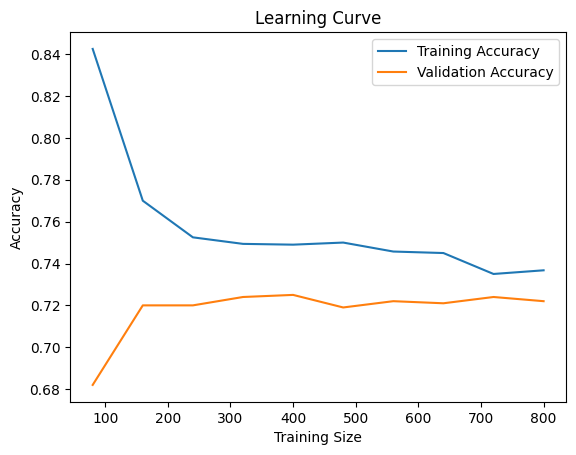

In [ ]:
# Learning Curve

train_sizes, train_scores, test_scores = learning_curve(
    grid_rf.best_estimator_, X_scaled, y,
    cv=5, train_sizes=np.linspace(0.1, 1.0, 10))

plt.plot(train_sizes, train_scores.mean(axis=1), label='Training Accuracy')
plt.plot(train_sizes, test_scores.mean(axis=1),  label='Validation Accuracy')
plt.xlabel('Training Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve')
plt.legend()
plt.show()

Conclusion:

Random Forest performed best overall after hyperparameter tuning.

It achieved the highest accuracy and F1 score compared to Logistic Regression and Decision Tree. Logistic Regression performed well and but could not capture the non-linear patterns in student data as effectively as Random Forest.

Decision Tree was the weakest model. It overfits, and even after tuning it could not match Random Forest because a single tree is less stable than an ensemble.
Random Forest is the best choice for this problem because it combines multiple trees to reduce overfitting, gives reliable predictions even on unseen student data.